In [29]:
import json
import pandas as pd
import numpy as np
from sklearn.metrics import precision_recall_fscore_support, precision_recall_curve, auc
import matplotlib.pyplot as plt
from transformers import AutoTokenizer
import pandas as pd
import numpy as np

#load data 
HX = pd.read_json("../../input/data/hatexplain_human_annotated.json")
HX = HX.transpose()
print(HX.iloc[0])

post_id                              1179055004553900032_twitter
annotators     [{'label': 'normal', 'annotator_id': 1, 'targe...
rationales                                                    []
post_tokens    [i, dont, think, im, getting, my, baby, them, ...
Name: 1179055004553900032_twitter, dtype: object


In [30]:
HX = HX.rename(columns={'post_id':'ids', 'post_tokens': 'text'})
HX['id'] = ['HX' + str(i) for i in range(1, len(HX) + 1)]
HX.set_index(['id'], inplace=True)
HX['text'] = [" ".join(HX.iloc[i]["text"]) for i in range(len(HX))]

#Sort by groups 
identity_groups = ['Asian', 'Islam', 'Jewish', 'African', 'Homosexual', 'Women', 'Caucasian', 'None']

targets_HX = [[HX.iloc[i]["annotators"][j]['target'] for j in range(3)] for i in range(len(HX))]
targets_HX = [targets_HX[i][0]+targets_HX[i][1]+targets_HX[i][2] for i in range(len(HX))]

label = []
target = []
for i in range(len(HX)):
    t = [targets_HX[i].count(identity_groups[j]) for j in range(8)]
    if t.count(max(t)) == 1:
        target.append(identity_groups[t.index(max(t))])
    else:
        target.append('Unequal')
    labels_HX = [HX.iloc[i]["annotators"][j]['label'] for j in range(3)]
    if labels_HX.count("normal") == 3:
        label.append(0)
    elif labels_HX.count("normal") == 0:
        label.append(1)
    else:
        label.append(2)

HX['true_label'] = label
HX['group'] = target

#Get where entries with unambigous group-identity and label(two or more agreeing)
HX = HX[(HX['true_label'] < 2) & (HX['group'] != 'Unequal')]

def load_data(dataset_name, api):
    file_paths = {
        'gpt': f'../../output/API_classification/gpt/{dataset_name}_aggregate/gpt_{dataset_name}_aggregate.csv',
        'amazon': f'../../output/API_classification/amazon/{dataset_name}_aggregate/amazon_{dataset_name}_aggregate.csv',
        'google': f'../../output/API_classification/google/{dataset_name}_aggregate/google_{dataset_name}_aggregate.csv',
        'microsoft': f'../../output/API_classification/microsoft/{dataset_name}_aggregate/microsoft_{dataset_name}_aggregate.csv',
        'perspective': f'../../output/API_classification/perspective/{dataset_name}_aggregate/perspective_{dataset_name}_aggregate.csv'
    }
    return pd.read_csv(file_paths[api])

def get_false(dataset_name, api, distance):
    file = load_data(dataset_name, api)
    index = file.index[file.loc[:, 'predicted_label'] - file.loc[:, 'true_label'] == distance].tolist()
    wrong = pd.DataFrame(file.loc[index])
    wrong = wrong.set_index(np.array(list(range(len(wrong)))))
    ids = 'id' if api == 'microsoft' or api == 'perspective' else 'ids'
    return wrong[[ids, 'text', 'score', 'predicted_label', 'true_label']]

# Load SHAP values from CSV files
shap_amazon = pd.read_csv('../../output/API_classification/shap/amazon/hatexplain/amazon_hatexplain.csv', delimiter= ',')
shap_google = pd.read_csv('../../output/API_classification/shap/google/hatexplain/google_hatexplain.csv', delimiter= ',')
shap_gpt = pd.read_csv('../../output/API_classification/shap/gpt/hatexplain/gpt_hatexplain.csv', delimiter= ',')
#shap_microsoft = pd.read_csv('../../output/API_classification/shap/microsoft/hatexplain/microsoft_hatexplain.csv', delimiter= ',')
#shap_perspective = pd.read_csv('../../output/API_classification/shap/perspective/hatexplain/perspective_hatexplain.csv', delimiter= ',')
print(HX.iloc[0])

ids                                 1179055004553900032_twitter
annotators    [{'label': 'normal', 'annotator_id': 1, 'targe...
rationales                                                   []
text          i dont think im getting my baby them white 9 h...
true_label                                                    0
group                                                      None
Name: HX1, dtype: object


In [31]:
# Example of setting a threshold for SHAP values
threshold = 0.5

In [32]:
# Function to calculate IOU
def calculate_iou(human_rationale, shap_pred):
    intersection = np.sum(np.logical_and(human_rationale, shap_pred))
    union = np.sum(np.logical_or(human_rationale, shap_pred))
    iou = intersection / union if union != 0 else 0
    return iou

In [33]:
def new_shap(tokens, shap_values, human_tokens, human_rationale):
    str_s = "".join(tokens)
    vals_s = np.zeros(len(str_s))
    new_s = np.zeros(len(human_rationale))
    i = 0 
    j = 0
    for s,v in zip(tokens,shap_values):
        vals_s[i:i+len(s)] = v
        i  += len(s)
    for k in range(len(human_rationale)-1):
        ind = str_s[j:].find(human_tokens[k+1])
        new_s[k] = vals_s[j:j+ind].mean()
        j += ind
    new_s[len(human_tokens)-1] = vals_s[j:].mean()
    return new_s

In [51]:
def id_keys(api):
    shap_values_df = pd.read_csv(f'../../output/API_classification/shap/{api}/hatexplain/{api}_hatexplain.csv', delimiter=',')

    # Pre-load the tokenized column and IDs
    tokenized_texts = shap_values_df['tokenized'].apply(json.loads).apply("".join)
    ids = shap_values_df['id'].values

    # Create a lookup dictionary for faster matching
    text_to_index = {text: idx for idx, text in HX['text'].items()}

    id_key = {}
    missing = []
    
    for i, eg in enumerate(tokenized_texts):
        if eg in text_to_index:
            id_key[ids[i]] = text_to_index[eg]
        else:
            missing.append(eg)
    
    return id_key

In [52]:
id_keys_amazon = id_keys('amazon')

In [53]:
id_keys_gpt = id_keys('gpt')

In [54]:
id_keys_google = id_keys('google')

In [55]:
print(id_keys_amazon)

{'HX2948': 'HX2345', 'HX975': 'HX5462', 'HX18681': 'HX7874', 'HX18980': 'HX14478', 'HX2946': 'HX975', 'HX9726': 'HX527', 'HX1132': 'HX535', 'HX1323': 'HX4387', 'HX18427': 'HX10194', 'HX5400': 'HX2948', 'HX14683': 'HX18681', 'HX18821': 'HX18980', 'HX17533': 'HX2946', 'HX20023': 'HX17533', 'HX10462': 'HX9726', 'HX15882': 'HX10462', 'HX7437': 'HX20023', 'HX18230': 'HX1323', 'HX2020': 'HX1132', 'HX14694': 'HX18427', 'HX9987': 'HX5400', 'HX6683': 'HX7437', 'HX8718': 'HX2020', 'HX3676': 'HX14683', 'HX10053': 'HX18821', 'HX5454': 'HX8718', 'HX9592': 'HX9987', 'HX6876': 'HX3676', 'HX6806': 'HX15882', 'HX7271': 'HX6876', 'HX15854': 'HX18230', 'HX11439': 'HX14694', 'HX3505': 'HX6806', 'HX18803': 'HX6683', 'HX9990': 'HX3505', 'HX18650': 'HX10053', 'HX2218': 'HX5454', 'HX10195': 'HX9990', 'HX7931': 'HX9592', 'HX8312': 'HX18803', 'HX16086': 'HX7271', 'HX4035': 'HX15854', 'HX15656': 'HX11439', 'HX13499': 'HX18650', 'HX3403': 'HX10195', 'HX6477': 'HX2218', 'HX4783': 'HX7931', 'HX8867': 'HX6477', 'HX4

In [89]:
def process_shap_values(api, distance,id_key):
    false_predictions = get_false('hatexplain', api, distance)

    shap_values_df = pd.read_csv(f'../../output/API_classification/shap/{api}/hatexplain/{api}_hatexplain.csv', delimiter=',')
    #id_key = id_keys(shap_values_df)
    
    shap_values_df['og_id']= shap_values_df['id'].map(id_key)
    shap_values_df = shap_values_df[shap_values_df['og_id'].isin(false_predictions['ids'])]
    HX_f = HX[HX.index.isin(false_predictions['ids'])]

    iou_dict = {}
    shap_dict = {}
    human_rationale_dict = {}
    for id, data in HX_f.iterrows():
        d = data['rationales']
        # Use the average of the annotators' rationales
        if len(d) == 0:
            print(0)
        elif not all(len(d[i]) == len(d[0]) for i in range(len(d))):
            print("different length")
        elif len(data['text'].split(" ")) != len(d[0]):
            print('different length to text')
        else:
            human_rationale = np.mean(np.array(data['rationales']), axis=0)
            shap_values = shap_values_df[shap_values_df['og_id'] == id]['shap_values'].apply(json.loads).values.tolist()
            tokens = shap_values_df[shap_values_df['og_id'] == id]['tokenized'].apply(json.loads).values.tolist()
            #print(id, data['text'], tokens)
            if len(shap_values) == 0:
                continue
            #make nans 0    
            shap_values = [np.nan_to_num(np.array(shap_values[i])) for i in range(len(shap_values))]
            shap_values = np.array(shap_values[0])
            # Remove first and last SHAP values
            shap_values = shap_values[1:-1]
            tokens[0] = tokens[0][1:-1]
            shap_values = new_shap(tokens[0], shap_values, data['text'].split(" "), human_rationale)
            iou = calculate_iou(human_rationale, shap_values)
            shap_dict[id] = shap_values
            iou_dict[id] = iou
            human_rationale_dict[id] = human_rationale
    return iou_dict, shap_dict, human_rationale_dict
        

In [90]:
# Calculate results for each API
amazon_results = process_shap_values('amazon', -1, id_keys_amazon)
google_results = process_shap_values('google', -1, id_keys_google)
gpt_results = process_shap_values('gpt', -1, id_keys_gpt)

C:\Users\ias-d\AppData\Local\Temp\ipykernel_71012\3048510832.py:12: RuntimeWarning: Mean of empty slice.
  new_s[k] = vals_s[j:j+ind].mean()
c:\Users\ias-d\anaconda3\envs\NLP\Lib\site-packages\numpy\core\_methods.py:129: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


different length to text


C:\Users\ias-d\AppData\Local\Temp\ipykernel_71012\3048510832.py:12: RuntimeWarning: Mean of empty slice.
  new_s[k] = vals_s[j:j+ind].mean()
c:\Users\ias-d\anaconda3\envs\NLP\Lib\site-packages\numpy\core\_methods.py:129: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)
C:\Users\ias-d\AppData\Local\Temp\ipykernel_71012\3048510832.py:12: RuntimeWarning: Mean of empty slice.
  new_s[k] = vals_s[j:j+ind].mean()
c:\Users\ias-d\anaconda3\envs\NLP\Lib\site-packages\numpy\core\_methods.py:129: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


In [72]:
def average_iou(results):
    return sum(1 for i in range(len(results)) if list(results.values())[i] >= 0.5 ) / len(results)

In [73]:
print(f"The average IOU for Amazon is {average_iou(amazon_results)}")
print(f"The average IOU for Google is {average_iou(google_results)}")
print(f"The average IOU for GPT is {average_iou(gpt_results)}")

The average IOU for Amazon is 0.29198606271777006
The average IOU for Google is 0.32280701754385965
The average IOU for GPT is 0.31738437001594894


In [74]:
def plot_sentence_with_iou(sentence, shap_values, rationales, iou):
    # Normalize the Shapley values for color mapping
    norm = plt.Normalize(min(shap_values), max(shap_values))
    cmap = plt.get_cmap('coolwarm')  # Colormap for Shapley values
    
    # Function to get color for each word based on Shapley values
    def get_color(value, is_rationale):
        color = cmap(norm(value))
        if is_rationale:
            # Darken the color for rationales to distinguish them
            color = tuple(np.clip(np.array(color) * 0.6, 0, 1))
        return color

    # Create subplots
    fig, axes = plt.subplots(1, 3, figsize=(15, 3), gridspec_kw={'width_ratios': [1, 0.2, 1]})
    
    # Plot Shapley values
    axes[0].axis('off')
    for i, word in enumerate(sentence):
        axes[0].text(i * 1.5, 0.5, word, fontsize=12, 
                     color=get_color(shap_values[i], rationales[i]), 
                     ha='center', va='center')
    axes[0].set_title('Shapley Values', fontsize=14)
    
    # Plot IoU in the middle
    axes[1].barh(['IoU'], [iou], color='gray', height=0.4)
    axes[1].set_xlim(0, 1)
    axes[1].set_xticks([0, 0.5, 1])
    axes[1].set_yticks([])
    axes[1].set_title('IoU', fontsize=14)
    
    # Plot Human-Annotated Rationales
    axes[2].axis('off')
    for i, word in enumerate(sentence):
        color = 'black' if rationales[i] else 'lightgray'
        axes[2].text(i * 1.5, 0.5, word, fontsize=12, 
                     color=color, 
                     ha='center', va='center')
    axes[2].set_title('Human Rationales', fontsize=14)
    
    plt.tight_layout()
    plt.show()

In [91]:
amazon_results

({'HX20': 0.08333333333333333,
  'HX29': 0.14285714285714285,
  'HX33': 0.2,
  'HX63': 0.09090909090909091,
  'HX74': 0.02631578947368421,
  'HX76': 0.03571428571428571,
  'HX92': 0.2,
  'HX113': 0.024390243902439025,
  'HX137': 1.0,
  'HX138': 0.11764705882352941,
  'HX140': 0.75,
  'HX145': 0.08333333333333333,
  'HX155': 0.14285714285714285,
  'HX180': 0.07142857142857142,
  'HX188': 0.2857142857142857,
  'HX189': 0.027777777777777776,
  'HX194': 0.125,
  'HX199': 0.125,
  'HX202': 0.3076923076923077,
  'HX248': 0.15789473684210525,
  'HX264': 0.07692307692307693,
  'HX266': 0.22916666666666666,
  'HX274': 0.125,
  'HX285': 0.04081632653061224,
  'HX287': 0.07894736842105263,
  'HX290': 0.09090909090909091,
  'HX296': 0.42857142857142855,
  'HX302': 0.5238095238095238,
  'HX316': 0.17391304347826086,
  'HX321': 0.043478260869565216,
  'HX322': 0.058823529411764705,
  'HX340': 0.046511627906976744,
  'HX352': 0.1111111111111111,
  'HX373': 0.16666666666666666,
  'HX376': 0.375,
  'HX

In [92]:
iou_dict, shap_dict, human_rationale_dict = amazon_results[0], amazon_results[1], amazon_results[2]

In [96]:
shap_dict

{'HX20': array([-0.02151785,  0.00143125,  0.02205313, -0.06750938, -0.07120625,
         0.09617875,  0.02413125, -0.00488126,  0.00483125, -0.01571875,
         0.009675  , -0.0419625 ]),
 'HX29': array([ 0.021275  , -0.0405625 , -0.0461375 , -0.01032499,  0.1042425 ,
        -0.0249625 ,  0.0135125 ]),
 'HX33': array([-0.048325  ,  0.01382813, -0.04071563, -0.0096875 ,  0.00726761,
        -0.00468125,  0.117525  ,  0.23555625, -0.00267501,  0.05965   ,
        -0.0095375 , -0.05145937,  0.04955312, -0.00300626,  0.00188056]),
 'HX63': array([-0.0159125 , -0.01593125, -0.03053125, -0.00275625, -0.03925625,
         0.03028125,  0.00105625, -0.01465   , -0.0334875 ,  0.10424   ,
        -0.00125982]),
 'HX74': array([ 2.20593745e-02, -2.89999973e-03, -1.41874980e-03, -4.49062372e-03,
        -6.60312315e-03, -1.00406250e-02, -1.70906233e-02,  5.96249802e-03,
         1.80843743e-02,  4.47674997e-02, -1.89640624e-02, -1.21609382e-02,
         1.15437505e-02,  1.32312507e-02, -4.349373

In [93]:
import spacy
from spacy import displacy

In [131]:
from IPython.display import display, HTML

In [156]:
def create_html_visualization(sentence, shap_values):
    # Normalize shap_values for consistent color mapping
    min_val, max_val = min(shap_values), max(shap_values)
    norm_shap_values = [(val - min_val) / (max_val - min_val) for val in shap_values]
    
    # Create a SpaCy Doc object manually
    nlp = spacy.blank("en")
    doc = nlp(" ".join(sentence))
    # Customize the token visualization by adding custom colors
    options = {
        "ents": [],  # No entities in this case
        "colors": {},
        "bg": "#ffffff",  # Background color of the entire text visualization
    }
    
    # Assign a color to each word based on its Shapley value
    # Customize the token visualization by adding custom colors
    options = {"ents": [], "colors": {}}
    
    # Assign a color to each word based on its Shapley value
    spans = []
    for i, token in enumerate(doc):
        shap_value = norm_shap_values[i]
        color = f"rgba(255, 0, 0, {shap_value})" if shap_value > 0 else f"rgba(0, 0, 255, {abs(shap_value)})"
        spans.append({
            "start": token.idx,
            "end": token.idx + len(token),
            "label": f"shap-{i}"
        })
        options["colors"][f"shap-{i}"] = color

    
    # Render the visualization in HTML
    html= displacy.render({"text": doc.text, "ents": spans}, style="ent", options=options, manual=True,jupyter=True)
    print(html)
    return html

In [157]:
a = create_html_visualization(HX.iloc[19]['text'].split(" "), shap_dict['HX20'])

AttributeError: 'spacy.tokens.doc.Doc' object has no attribute 'get'

rag
-0.19111323103697941


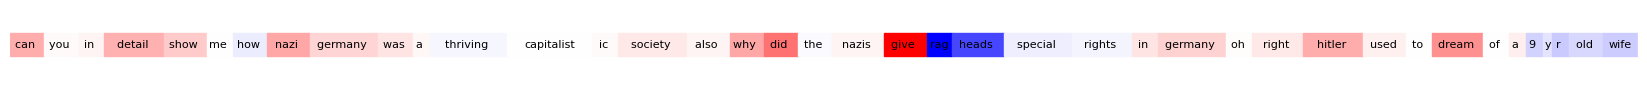

In [171]:
from matplotlib.patches import Rectangle

shap_values_gpt = pd.read_csv(f'../../output/API_classification/shap/gpt/hatexplain/gpt_hatexplain.csv', delimiter=',')
# Example sentence and token values
token_values = shap_values_gpt['shap_values'].apply(json.loads).values.tolist()[50]


# Split the sentence into tokens
tokens = shap_values_gpt['tokenized'].apply(json.loads).values.tolist()[50]
# Create a figure and axis
fig, ax = plt.subplots(figsize=(len(tokens)*0.5, 1))  # Adjust figure size based on the number of tokens

# Set the axis limits
#ax.set_xlim(0, 1)
#ax.set_ylim(0, 1)

# Hide the axes
ax.axis('off')

# Calculate the width of each token
total_length = sum(len(token) for token in tokens)
token_widths = [len(token) / total_length for token in tokens]
color_values = (np.array(token_values) + abs(min(token_values))) / (max(token_values)-min(token_values))

# Plot each token with a background color based on its value
x = 0
for token, value, width in zip(tokens, color_values, token_widths):
    
    ax.add_patch(Rectangle((x, 0.4), width, 0.3, color=plt.cm.bwr(value)))
    ax.text(x + width / 2, 0.55, token, ha='center', va='center', fontsize=8, color='black')  # Adjust font size
    x += width

plt.show()

In [159]:
shap_values_gpt['shap_values'].apply(json.loads).values.tolist()[50]

[0.0010051853264485544,
 0.044560460834418336,
 -0.01003407639427678,
 -0.005709694223241968,
 0.04050974414940356,
 0.022643766666533338,
 -0.01241728563536526,
 -0.026160432889355434,
 0.047962039044455555,
 0.01675357958195072,
 0.004658907425035733,
 -0.007738492212812406,
 -0.020507472444879812,
 -0.013430129473067248,
 -0.010115788287452781,
 0.0018242652602797505,
 -0.006307508882104779,
 0.048704487640601916,
 0.0841715013572996,
 -0.01727673240774103,
 -0.005473560228243254,
 0.16380950577487446,
 -0.19111323103697941,
 -0.14155813466186373,
 -0.024901419451452966,
 -0.021210418587543245,
 0.00545868256722315,
 0.01783717682246788,
 -0.011026102530195203,
 0.0019734961633730563,
 0.04341519089030044,
 -0.00330210290303512,
 -0.013536895736251608,
 0.06349586172109412,
 -0.014203675967837625,
 -0.001470778082693868,
 -0.044444589350678146,
 -0.03228298483081744,
 -0.05085941824727343,
 -0.04119290833720394,
 -0.04922533294544943,
 -0.0013805384830144856]

In [152]:
print(a)

None


In [142]:
display(HTML(a))

<IPython.core.display.HTML object>

In [128]:
with open("a.html", "w") as file:
    file.write(HTML(a))

TypeError: write() argument must be str, not HTML

In [ ]:
def plot_sentence_shap(sentence, shap_values, human_rationale):
    norm = plt.Normalize(min(shap_values), max(shap_values))
    cmap = plt.get_cmap('viridis')  # Colormap for Shapley values
    
    def get_color(value, is_rationale):
        color = cmap(norm(value))
        if is_rationale:
            # Darken the color for rationales to distinguish them
            color = tuple(np.clip(np.array(color) * 0.6, 0, 1))
        return color
    

    


In [81]:
def process_and_visualize(api, distance, id_key):
    false_predictions = get_false('hatexplain', api, distance)
    shap_values_df = pd.read_csv(f'../../output/API_classification/shap/{api}/hatexplain/{api}_hatexplain.csv', delimiter=',')
    
    shap_values_df['og_id'] = shap_values_df['id'].map(id_key)
    shap_values_df = shap_values_df[shap_values_df['og_id'].isin(false_predictions['ids'])]
    HX_f = HX[HX.index.isin(false_predictions['ids'])]
    i = 0
    for id, data in HX_f.iterrows():
        if i >2:
            break
        i+=1 
        d = data['rationales']
        if len(d) == 0 or len(data['text'].split(" ")) != len(d[0]):
            continue

        human_rationale = np.mean(np.array(data['rationales']), axis=0)
        shap_values = shap_values_df[shap_values_df['og_id'] == id]['shap_values'].apply(json.loads).values.tolist()
        tokens = shap_values_df[shap_values_df['og_id'] == id]['tokenized'].apply(json.loads).values.tolist()
        
        if len(shap_values) == 0:
            continue

        shap_values = np.nan_to_num(np.array(shap_values[0]))
        shap_values = shap_values[1:-1]
        tokens[0] = tokens[0][1:-1]
        shap_values = new_shap(tokens[0], shap_values, data['text'].split(" "), human_rationale)
        iou = calculate_iou(human_rationale, shap_values)
        
        plot_sentence_with_iou(data['text'].split(" "), shap_values, human_rationale, iou)

C:\Users\ias-d\AppData\Local\Temp\ipykernel_71012\3918715424.py:41: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


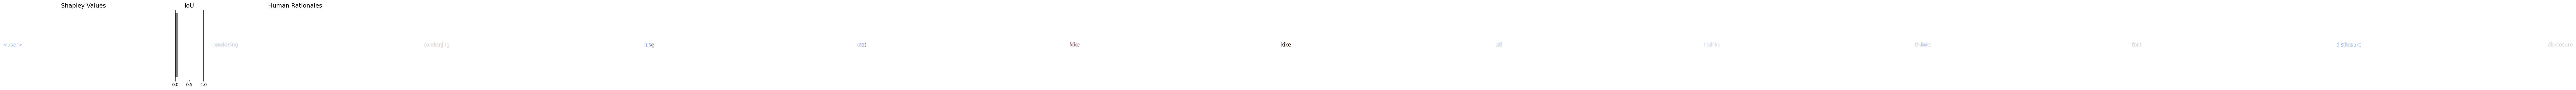

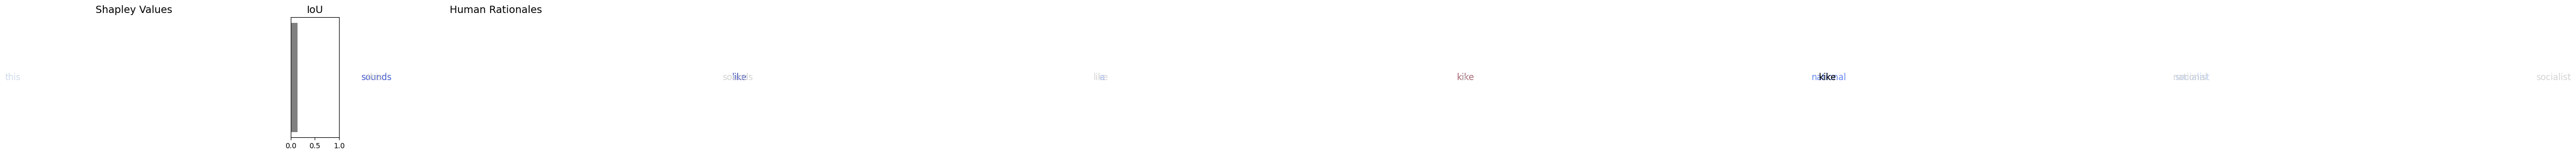



In [82]:
process_and_visualize('amazon', -1, id_keys_amazon)